# 02 - Data Cleaning

This notebook applies the cleaning pipeline defined in `src/preprocessing.py`: missing-value handling, duplicate removal, data-type conversion, and outlier inspection using the IQR method.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data_loader
import preprocessing

sns.set_style('whitegrid')

In [2]:
raw = data_loader.load_raw_data()
raw.shape

(9994, 21)

## Missing values (before cleaning)

In [3]:
missing = raw.isnull().sum()
missing[missing > 0] if missing.sum() > 0 else 'No missing values detected.'

'No missing values detected.'

## Duplicate rows (before cleaning)

In [4]:
print('Duplicate rows:', raw.duplicated().sum())

Duplicate rows: 0


## Type conversion

`Order Date`/`Ship Date` -> datetime, `Sales`/`Quantity`/`Discount`/`Profit` -> numeric, and low-cardinality text columns -> `category` dtype for memory efficiency.

In [5]:
typed = preprocessing.convert_data_types(raw)
typed.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode              category
Customer ID                 str
Customer Name               str
Segment                category
Country                category
City                   category
State                  category
Postal Code               int64
Region                 category
Product ID                  str
Category               category
Sub-Category           category
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

## Handling missing values

**Strategy** (see `preprocessing.handle_missing_values` docstring):
- Numeric columns central to the analysis (`Sales`, `Quantity`, `Discount`, `Profit`) are filled with the column **median** - these fields are typically right-skewed, and the median is more robust to outliers than the mean.
- Categorical columns are filled with the literal string `'Unknown'` rather than the mode, so we don't silently overstate the size of the most common category.
- Rows missing `Order Date` are dropped, since there is no reliable way to impute a transaction date and every time-based feature depends on it.

In [6]:
cleaned = preprocessing.handle_missing_values(typed)
cleaned.shape

(9994, 21)

## Removing duplicates

Only exact duplicate rows are removed - partial matches (e.g. two different products ordered by the same customer on the same day) are legitimate distinct transactions and are kept.

In [7]:
cleaned = preprocessing.remove_duplicates(cleaned)
cleaned.shape

Removed 0 duplicate rows out of 9994.


(9994, 21)

## Outlier analysis (IQR method)

We inspect outliers but **do not automatically delete them**: a $20,000 office-chair order or a heavily discounted clearance sale are legitimate business transactions, not data-entry errors, so removing them would distort the sales and profit picture rather than clean it.

In [8]:
outlier_summary = preprocessing.analyze_outliers(cleaned)
outlier_summary

,column,Q1,Q3,IQR,lower_bound,upper_bound,num_outliers,pct_outliers
0,Sales,17.28000,209.940,192.66000,-271.710000,498.930000,1167,11.68
1,Quantity,2.00000,5.000,3.00000,-2.500000,9.500000,170,1.70
2,Discount,0.00000,0.200,0.20000,-0.300000,0.500000,856,8.57
3,Profit,1.72875,29.364,27.63525,-39.724125,70.816875,1881,18.82


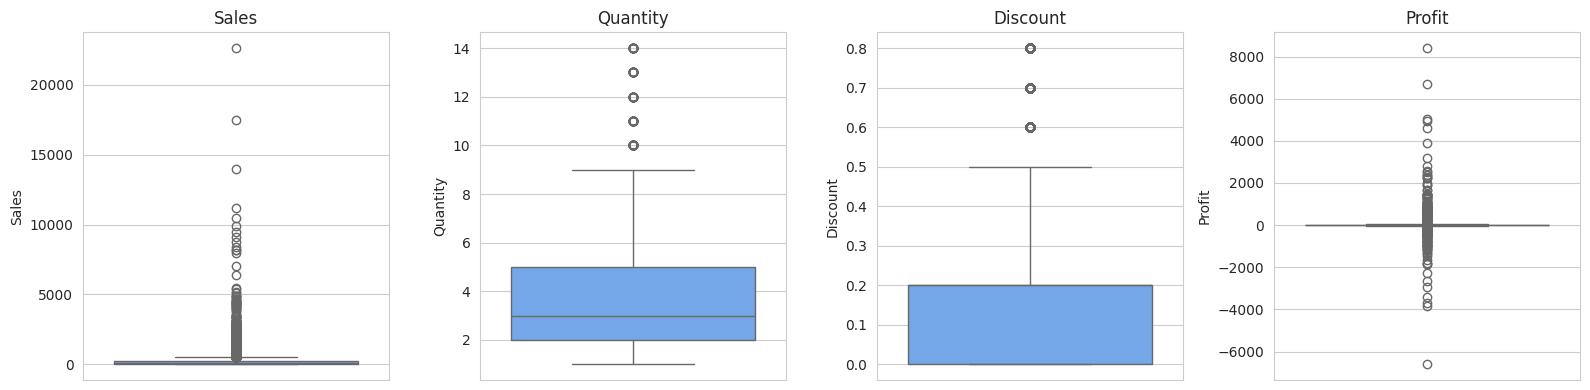

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['Sales', 'Quantity', 'Discount', 'Profit']):
    sns.boxplot(y=cleaned[col], ax=ax, color='#60a5fa')
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** `Sales` and `Profit` show a meaningful share of IQR-flagged points, consistent with a retail dataset that mixes small everyday purchases with large bulk/technology orders. `Profit` even includes negative values (loss-making, heavily-discounted orders), which are legitimate and informative rather than data errors, so all rows are kept for the analysis stages that follow.

## Export the cleaned dataset

In [10]:
cleaned.to_csv('../data/processed/cleaned_sales.csv', index=False)
print('Saved cleaned dataset:', cleaned.shape)

Saved cleaned dataset: (9994, 21)
